# Informe Trabajo Práctico de Laboratorio 2

## Teoría de Circuitos II

## Alumno
### Juan Manuel Miranda Del Valle

## Institución
### Universidad Tecnologica Nacional

## Profesores
### Mariano Llamedo Soria y César Fouco

### Introduccion

<div align="center">
    <img src="1.png" width="800">
</div>

<div align="center">
    <img src="2.png" width="800">
</div>

## Introduccion <a id="intro"></a>
En el presente trabajo de laboratorio se implementaron los filtros solicitados por la cátedra.

El objetivo principal de la experiencia fue analizar y comparar las ventajas y desventajas del filtrado digital frente al analógico, considerando aspectos como la exactitud, la velocidad de respuesta, la flexibilidad de diseño, el tiempo de desarrollo y la complejidad asociada a cada alternativa.

El desarrollo del trabajo se dividió en distintas etapas correspondientes al diseño, la simulación y la validación experimental. En primer lugar, se realizó el diseño de los filtros digitales utilizando las herramientas `arm_fir_f32` e `iirdesign`, según correspondiera, verificando en cada caso el cumplimiento de las plantillas especificadas. Una vez obtenidos los coeficientes de los filtros, estos fueron incorporados al proyecto desarrollado en STM32CubeIDE para su implementación en el microcontrolador utilizado.

Para el funcionamiento del sistema también fue necesario incorporar dos filtros pasabajos analógicos, ubicados respectivamente en la entrada del ADC y en la salida del DAC de la placa.

Finalmente, durante la etapa experimental se realizaron las mediciones necesarias para la elaboración del presente informe. Estas incluyeron un barrido en frecuencia mediante un osciloscopio digital y otro utilizando un analizador de espectros, con el objetivo de comparar el comportamiento real de los filtros con los resultados teóricos y simulados.


## Análisis y Simulacion ( Pre-Lab )<a id="prelab"></a>

### Diseño del filtro Pasabajos Chebyshev:


NameError: name 'group_delay' is not defined

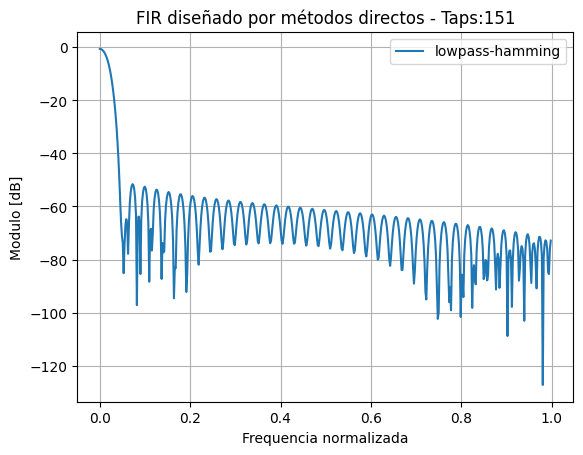

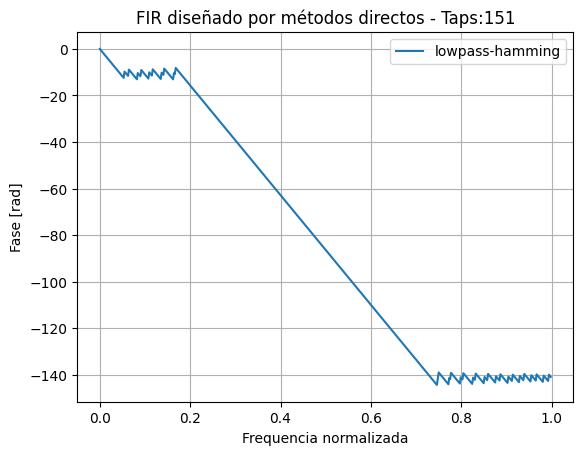

<Figure size 640x480 with 0 Axes>

In [14]:
import sympy as sp
import numpy as np
import scipy.signal as sig
from scipy.signal.windows import hamming, kaiser, blackmanharris
import matplotlib.pyplot as plt

from pytc2.sistemas_lineales import plot_plantilla

# frecuencia de muestreo normalizada
fs = 20*10**3
# tamaño de la respuesta al impulso
cant_coef = 151

filter_type = 'lowpass'

fpass = 100 # 
ripple = 1 # dB
fstop = 300 # Hz
attenuation = 60 # dB

f_predist = 60  #Hz

# construyo la plantilla de requerimientos
frecs = [0.0,  fpass + f_predist,   fstop - f_predist ,   fs/2]
gains = [0,   -ripple, -attenuation,   -np.inf] # dB

gains = 10**(np.array(gains)/20)


# FIR design
#num_bh = sig.firwin2(cant_coef, frecs, gains , window='blackmanharris' , 1000)
num_hm = sig.firwin2(cant_coef, frecs, gains , window='hamming', fs=fs)
#num_ka = sig.firwin2(cant_coef, frecs, gains , window=('kaiser',14) , fs=f1/2
                     
den = 1.0



def plot_freq_resp_fir(this_num, this_desc):

    wrad, hh = sig.freqz(this_num, 1.0)
    ww = wrad / np.pi
    
    plt.figure(1)

    plt.plot(ww, 20 * np.log10(abs(hh)), label=this_desc)

    plt.title('FIR diseñado por métodos directos - Taps:' + str(cant_coef) )
    plt.xlabel('Frequencia normalizada')
    plt.ylabel('Modulo [dB]')
    plt.grid(which='both', axis='both')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    
    plt.figure(2)

    phase = np.unwrap(np.angle(hh))

    plt.plot(ww, phase, label=this_desc)

    plt.title('FIR diseñado por métodos directos - Taps:' + str(cant_coef))
    plt.xlabel('Frequencia normalizada')
    plt.ylabel('Fase [rad]')
    plt.grid(which='both', axis='both')

    axes_hdl = plt.gca()
    axes_hdl.legend()

    plt.figure(3)

    gd_win = group_delay(wrad, phase)

    plt.plot(ww, gd_win, label=this_desc)

    plt.ylim((np.min(gd_win[2:-2])-1, np.max(gd_win[2:-2])+1))
    plt.title('FIR diseñado por métodos directos - Taps:' + str(cant_coef))
    plt.xlabel('Frequencia normalizada')
    plt.ylabel('Retardo [# muestras]')
    plt.grid(which='both', axis='both')

    axes_hdl = plt.gca()
    axes_hdl.legend()    

plt.close('all')

#plot_freq_resp_fir(num_bh, filter_type+ '-blackmanharris')    
plot_freq_resp_fir(num_hm, filter_type+ '-hamming')    
#plot_freq_resp_fir(num_ka, filter_type+ '-kaiser-b14')    
    
    
# sobreimprimimos la plantilla del filtro requerido para mejorar la visualización    
fig = plt.figure(1)    
plot_plantilla(filter_type = filter_type,
                fpass = fpass/(fs/2),
                ripple = ripple,
                fstop = fstop/(fs/2),
                attenuation = attenuation,
                fs = 2)
ax = plt.gca()
ax.legend()

# reordenamos las figuras en el orden habitual: módulo-fase-retardo
plt.figure(2)    
axes_hdl = plt.gca()
axes_hdl.legend()

plt.figure(3)    
axes_hdl = plt.gca()
axes_hdl.legend()

print(num_hm)

plt.show()

### Diseño de filtro Notch IIR y obtencion de coeficientes

SOS:
[[ 0.99984295 -1.99943919  0.99984295  1.         -1.99943919  0.99968589]]


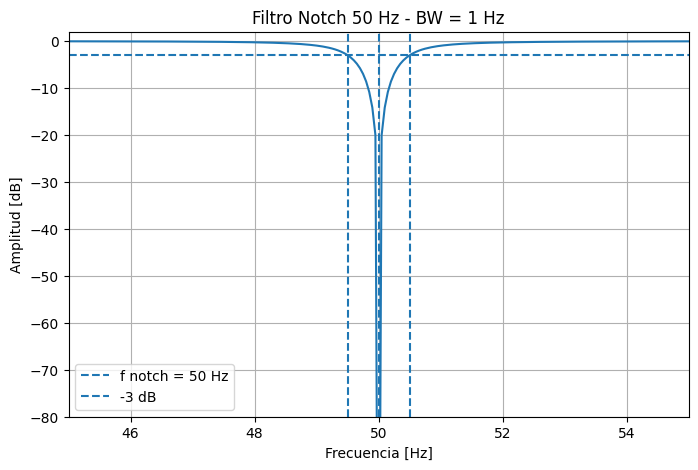

In [3]:
import numpy as np
from scipy import signal as sig
import sympy as sp
from matplotlib import pyplot as plt
from pytc2.remociones import remover_polo_dc
from pytc2.general import a_equal_b_latex_s, print_latex, s, symbfunc2tf, factorSOS
from pytc2.sistemas_lineales import bodePlot, pzmap, GroupDelay, analyze_sys
from pytc2.sistemas_lineales import pretty_print_lti
from pytc2.general import print_latex, a_equal_b_latex_s
from pytc2.cuadripolos import calc_MAI_ztransf_ij_mn
from pytc2.cuadripolos import calc_MAI_vtransf_ij_mn
import sympy as sp


# Especificaciones
f0 = 50.0
BW = 1.0
fs_muestreo = 20000.0

# Factor de calidad
Q = f0 / BW

# Filtro notch
b, a = sig.iirnotch(f0, Q, fs=fs_muestreo)

# Lo paso a SOS para trabajar igual que antes
sos = sig.tf2sos(b, a)

print("SOS:")
print(sos)

# Respuesta en frecuencia
w, h = sig.sosfreqz(
    sos,
    worN=200000,
    fs=fs_muestreo
)

plt.figure(figsize=(8,5))

plt.plot(
    w,
    20*np.log10(np.maximum(np.abs(h), 1e-8))
)

plt.axvline(f0, linestyle='--', label='f notch = 50 Hz')

# Bordes de BW de 1 Hz
plt.axvline(49.5, linestyle='--')
plt.axvline(50.5, linestyle='--')

plt.axhline(-3, linestyle='--', label='-3 dB')

plt.xlim(45, 55)
plt.ylim(-80, 2)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.title('Filtro Notch 50 Hz - BW = 1 Hz')

plt.grid(True)
plt.legend()
plt.show()

## Mediciones, con Analizador de espectros <a id="medicion"></a>
Se utilizó un analizador de espectros para obtener y analizar la respuesta en frecuencia de tres configuraciones de filtrado diferentes.

En primer lugar, se implementó un filtro pasatodo en el microcontrolador, con el objetivo de evaluar la atenuación introducida únicamente por los filtros analógicos ubicados en la entrada y salida del sistema, destinados a reducir los efectos del aliasing y las imágenes espectrales, respectivamente.

La respuesta obtenida muestra una atenuación de aproximadamente 3.5 dB para frecuencias superiores a 4 kHz. Este comportamiento resulta esperable debido a la simplicidad de los filtros analógicos empleados, constituidos por circuitos RC pasabajos de una sola etapa.

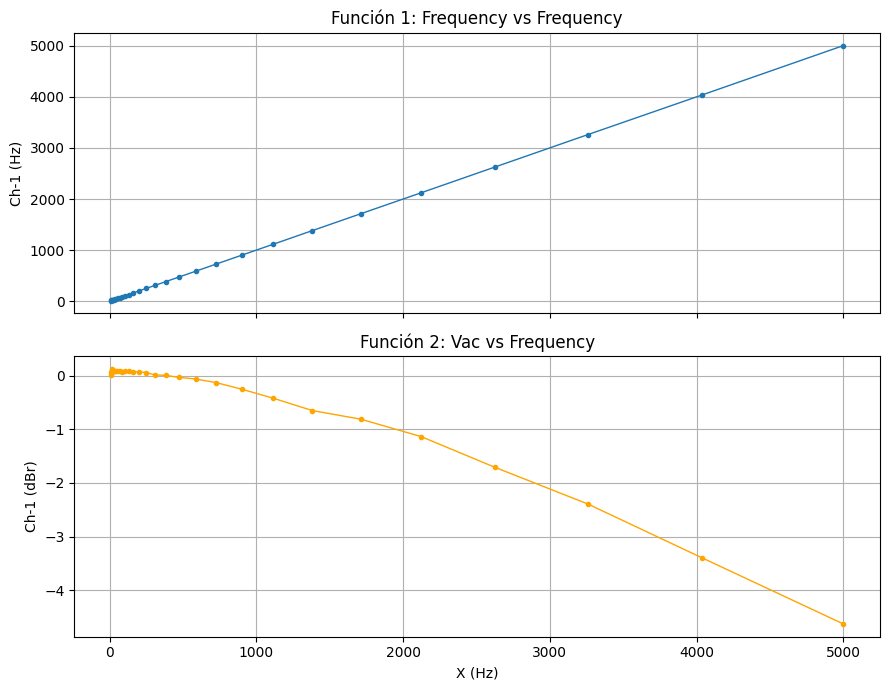

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import re

path = "Sweep Data_2.csv"  # cambiá por la ruta real de tu archivo

with open(path, "r", encoding="utf-8", errors="ignore") as f:
    lines = f.readlines()

def parse_block(lines_block):
    rows = []
    for line in lines_block:
        line = line.strip()
        if not line or "Sweep" in line or "vs Frequency" in line or "Ch-1" in line:
            continue
        parts = line.split(",")
        # nos quedamos solo con filas bien formadas: "numero,numero"
        if len(parts) == 2:
            try:
                x = float(parts[0])
                y = float(parts[1])
                rows.append((x, y))
            except ValueError:
                continue  # descarta filas corruptas tipo "480.961.843..."
    return pd.DataFrame(rows, columns=["Frequency_Hz", "Value"])

# separamos el archivo en los dos bloques (Function 1 y Function 2)
split_idx = next(i for i, l in enumerate(lines) if "Function 2" in l)

df1 = parse_block(lines[:split_idx])
df2 = parse_block(lines[split_idx:])

fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axs[0].plot(df1["Frequency_Hz"], df1["Value"], marker=".", lw=1)
axs[0].set_ylabel("Ch-1 (Hz)")
axs[0].set_title("Función 1: Frequency vs Frequency")
axs[0].grid(True)

axs[1].plot(df2["Frequency_Hz"], df2["Value"], marker=".", lw=1, color="orange")
axs[1].set_ylabel("Ch-1 (dBr)")
axs[1].set_xlabel("X (Hz)")
axs[1].set_title("Función 2: Vac vs Frequency")
axs[1].grid(True)

plt.tight_layout()
plt.show()

2. A partir del barrido en frecuencia del filtro pasabajos, se obtuvo una respuesta acorde con la esperada, alcanzando una atenuación cercana a los 60 dB alrededor de los 500 Hz. Sin embargo, se observaron algunos puntos aislados en la región de bajas frecuencias que podrían atribuirse a la presencia de ruido o interferencias durante la medición, posiblemente relacionados con el montaje experimental realizado sobre una protoboard.

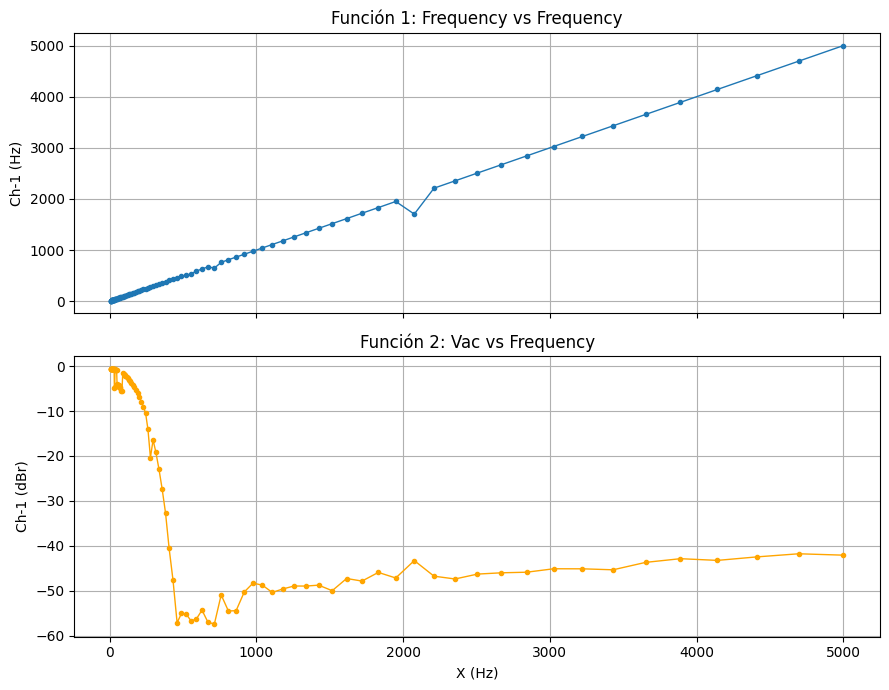

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import re

path = "Sweep Data_1.csv"  # cambiá por la ruta real de tu archivo

with open(path, "r", encoding="utf-8", errors="ignore") as f:
    lines = f.readlines()

def parse_block(lines_block):
    rows = []
    for line in lines_block:
        line = line.strip()
        if not line or "Sweep" in line or "vs Frequency" in line or "Ch-1" in line:
            continue
        parts = line.split(",")
        # nos quedamos solo con filas bien formadas: "numero,numero"
        if len(parts) == 2:
            try:
                x = float(parts[0])
                y = float(parts[1])
                rows.append((x, y))
            except ValueError:
                continue  # descarta filas corruptas tipo "480.961.843..."
    return pd.DataFrame(rows, columns=["Frequency_Hz", "Value"])

# separamos el archivo en los dos bloques (Function 1 y Function 2)
split_idx = next(i for i, l in enumerate(lines) if "Function 2" in l)

df1 = parse_block(lines[:split_idx])
df2 = parse_block(lines[split_idx:])

fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axs[0].plot(df1["Frequency_Hz"], df1["Value"], marker=".", lw=1)
axs[0].set_ylabel("Ch-1 (Hz)")
axs[0].set_title("Función 1: Frequency vs Frequency")
axs[0].grid(True)

axs[1].plot(df2["Frequency_Hz"], df2["Value"], marker=".", lw=1, color="orange")
axs[1].set_ylabel("Ch-1 (dBr)")
axs[1].set_xlabel("X (Hz)")
axs[1].set_title("Función 2: Vac vs Frequency")
axs[1].grid(True)

plt.tight_layout()
plt.show()

3. A partir del barrido en frecuencia del filtro IIR Notch, se observó que la atenuación máxima medida no alcanzó los 80 dB previstos durante la etapa de diseño. Esta diferencia podría atribuirse a la cantidad limitada de puntos utilizados en el barrido, debido a la necesidad de optimizar el tiempo disponible en el laboratorio para que todos los grupos pudieran realizar sus mediciones.

Dado que este tipo de filtro presenta una banda de rechazo estrecha, es posible que el barrido no haya coincidido exactamente con la frecuencia de máxima atenuación. Por lo tanto, un barrido con mayor resolución en frecuencia permitiría caracterizar con mayor precisión la profundidad del rechazo y verificar su correspondencia con los resultados teóricos.

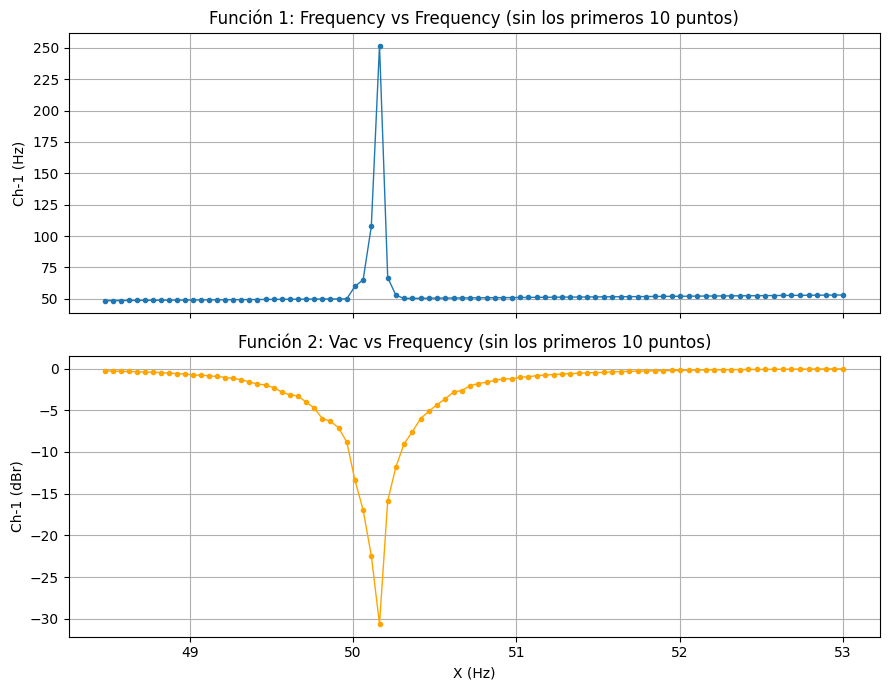

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

path = "Sweep Data_0.csv"  

with open(path, "r", encoding="utf-8", errors="ignore") as f:
    lines = f.readlines()

def parse_block(lines_block, skip_first=0):
    rows = []
    for line in lines_block:
        line = line.strip()
        if not line or "Sweep" in line or "vs Frequency" in line or "Ch-1" in line:
            continue
        parts = line.split(",")
        if len(parts) == 2:
            try:
                x = float(parts[0])
                y = float(parts[1])
                rows.append((x, y))
            except ValueError:
                continue  # descarta filas corruptas tipo "480.961.843..."
    df = pd.DataFrame(rows, columns=["Frequency_Hz", "Value"])
    if skip_first > 0:
        df = df.iloc[skip_first:].reset_index(drop=True)
    return df

# separamos el archivo en los dos bloques (Function 1 y Function 2)
split_idx = next(i for i, l in enumerate(lines) if "Function 2" in l)

df1 = parse_block(lines[:split_idx], skip_first=10)
df2 = parse_block(lines[split_idx:], skip_first=10)

fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axs[0].plot(df1["Frequency_Hz"], df1["Value"], marker=".", lw=1)
axs[0].set_ylabel("Ch-1 (Hz)")
axs[0].set_title("Función 1: Frequency vs Frequency (sin los primeros 10 puntos)")
axs[0].grid(True)

axs[1].plot(df2["Frequency_Hz"], df2["Value"], marker=".", lw=1, color="orange")
axs[1].set_ylabel("Ch-1 (dBr)")
axs[1].set_xlabel("X (Hz)")
axs[1].set_title("Función 2: Vac vs Frequency (sin los primeros 10 puntos)")
axs[1].grid(True)

plt.tight_layout()
plt.show()

## Comparacion con los filtros diseñados

A contincuacion se graficaran los filtros diseñados con los obtenidos en los barridos en frecuencia

1. Al comparar la respuesta en frecuencia medida con la obtenida durante el diseño del filtro FIR, se observa una buena correspondencia en la banda de paso y en la zona de transición. Sin embargo, a medida que aumenta la frecuencia, aparece una diferencia considerable entre ambas respuestas, especialmente en la banda de rechazo.

Una posible causa de esta discrepancia es el efecto de aliasing, producido por componentes de alta frecuencia que no fueron suficientemente atenuadas antes del muestreo. Asimismo, la presencia de imágenes espectrales a la salida del DAC podría contribuir a las diferencias observadas.

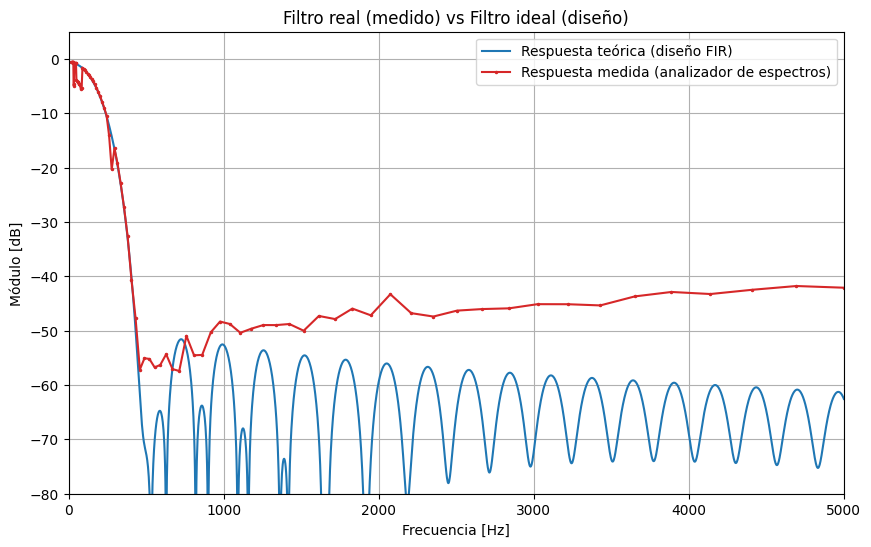

In [9]:
import pandas as pd
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt

# ---------- 1) Cargar y parsear el CSV medido ----------

path = "Sweep Data_1.csv"  # ajustá la ruta

with open(path, "r", encoding="utf-8", errors="ignore") as f:
    lines = f.readlines()

def parse_block(lines_block, skip_first=0):
    rows = []
    for line in lines_block:
        line = line.strip()
        if not line or "Sweep" in line or "vs Frequency" in line or "Ch-1" in line:
            continue
        parts = line.split(",")
        if len(parts) == 2:
            try:
                x = float(parts[0])
                y = float(parts[1])
                rows.append((x, y))
            except ValueError:
                continue
    df = pd.DataFrame(rows, columns=["Frequency_Hz", "Value"])
    if skip_first > 0:
        df = df.iloc[skip_first:].reset_index(drop=True)
    return df

split_idx = next(i for i, l in enumerate(lines) if "Function 2" in l)
df_medido = parse_block(lines[split_idx:], skip_first=10)  # dBr vs Hz medidos

# ---------- 2) Respuesta teórica del filtro diseñado, en Hz ----------

n_puntos = 4096
wrad, hh = sig.freqz(num_hm, 1.0, worN=n_puntos, fs=fs)  # fs en Hz -> wrad sale en Hz
h_db_teorico = 20 * np.log10(np.abs(hh))

# ---------- 3) Gráfico comparativo ----------

plt.figure(figsize=(10, 6))
plt.plot(wrad, h_db_teorico, label='Respuesta teórica (diseño FIR)', color='tab:blue')
plt.plot(df_medido["Frequency_Hz"], df_medido["Value"], 
         label='Respuesta medida (analizador de espectros)', 
         color='tab:red', marker='.', linestyle='-', markersize=3)

plt.title('Filtro real (medido) vs Filtro ideal (diseño)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.xlim(0, max(df_medido["Frequency_Hz"].max(), fpass*3))  # ajustá el rango si querés ver más/menos
plt.ylim(-80, 5)
plt.grid(which='both', axis='both')
plt.legend()
plt.show()

2. Al comparar la respuesta en frecuencia medida del filtro IIR Notch con la obtenida durante el diseño, se observa una buena correspondencia general entre ambas curvas, especialmente fuera de la banda de rechazo, donde la ganancia se mantiene cercana a los 0 dB.

En las proximidades de los 50 Hz se presentan las principales diferencias. Mientras que el filtro teórico alcanza una atenuación de 80 dB, el filtro implementado presenta una atenuación máxima cercana a los 30 dB, lo que representa una reducción considerable de la amplitud de la señal.

Asimismo, se observa un pequeño desplazamiento de la frecuencia de máximo rechazo hacia valores ligeramente superiores a los 50 Hz, junto con una leve diferencia en el ancho de banda respecto del diseño original.

Estas discrepancias podrían estar relacionadas con la resolución del barrido en frecuencia, las limitaciones del sistema de medición o las características de la implementación experimental.

En términos generales, los resultados permiten verificar el correcto funcionamiento del filtro digital y su capacidad para atenuar selectivamente una frecuencia determinada, manteniendo prácticamente inalteradas las componentes ubicadas fuera de la banda de rechazo.

SOS:
[[ 0.99984295 -1.99943919  0.99984295  1.         -1.99943919  0.99968589]]


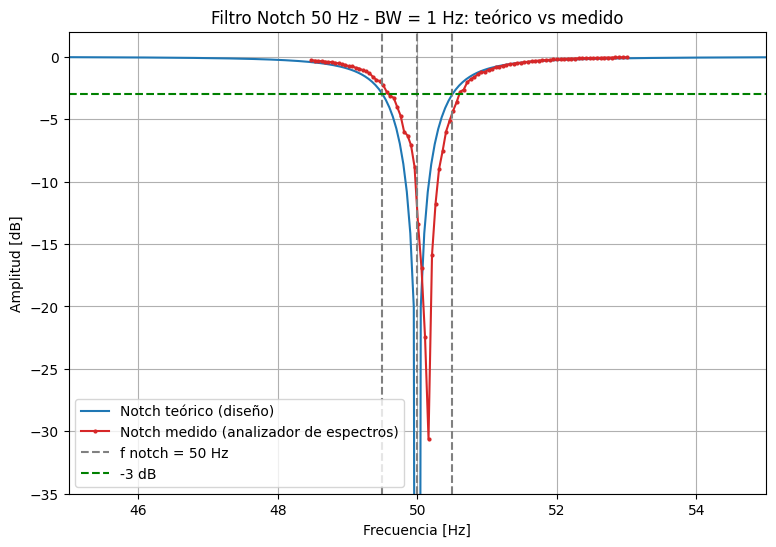

In [11]:
import numpy as np
import pandas as pd
from scipy import signal as sig
from matplotlib import pyplot as plt

# ---------- 1) Cargar y parsear el CSV medido ----------

path = "Sweep Data_0.csv"  # ajustá la ruta

with open(path, "r", encoding="utf-8", errors="ignore") as f:
    lines = f.readlines()

def parse_block(lines_block, skip_first=0):
    rows = []
    for line in lines_block:
        line = line.strip()
        if not line or "Sweep" in line or "vs Frequency" in line or "Ch-1" in line:
            continue
        parts = line.split(",")
        if len(parts) == 2:
            try:
                x = float(parts[0])
                y = float(parts[1])
                rows.append((x, y))
            except ValueError:
                continue
    df = pd.DataFrame(rows, columns=["Frequency_Hz", "Value"])
    if skip_first > 0:
        df = df.iloc[skip_first:].reset_index(drop=True)
    return df

split_idx = next(i for i, l in enumerate(lines) if "Function 2" in l)
df_medido = parse_block(lines[split_idx:], skip_first=10)  # dBr vs Hz medidos

# ---------- 2) Diseño teórico del notch (tu código original) ----------

f0 = 50.0
BW = 1.0
fs_muestreo = 20000.0

Q = f0 / BW

b, a = sig.iirnotch(f0, Q, fs=fs_muestreo)
sos = sig.tf2sos(b, a)

print("SOS:")
print(sos)

w, h = sig.sosfreqz(sos, worN=200000, fs=fs_muestreo)
h_db_teorico = 20*np.log10(np.maximum(np.abs(h), 1e-8))

# ---------- 3) Gráfico comparativo: medido vs teórico ----------

plt.figure(figsize=(9,6))

plt.plot(w, h_db_teorico, label='Notch teórico (diseño)', color='tab:blue')
plt.plot(df_medido["Frequency_Hz"], df_medido["Value"],
         label='Notch medido (analizador de espectros)',
         color='tab:red', marker='.', linestyle='-', markersize=4)

plt.axvline(f0, linestyle='--', color='gray', label='f notch = 50 Hz')
plt.axvline(49.5, linestyle='--', color='gray')
plt.axvline(50.5, linestyle='--', color='gray')

plt.axhline(-3, linestyle='--', color='green', label='-3 dB')

plt.xlim(45, 55)
plt.ylim(-35, 2)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.title('Filtro Notch 50 Hz - BW = 1 Hz: teórico vs medido')

plt.grid(True)
plt.legend()
plt.show()

## Conclusión

A partir de esta experiencia de laboratorio, se logró implementar y verificar el funcionamiento de los filtros digitales solicitados por la cátedra, cumpliendo en términos generales con los objetivos planteados. Si bien las respuestas obtenidas experimentalmente presentaron algunas diferencias respecto de las teóricas, los resultados permitieron comprobar el comportamiento esperado de los filtros.

Por otra parte, se identificaron posibles mejoras en el montaje experimental, como reemplazar la protoboard por una placa de circuito impreso que garantice conexiones más firmes y confiables, así como implementar filtros analógicos antialiasing y de reconstrucción con mejores características de atenuación.

Finalmente, la experiencia permitió demostrar una de las principales ventajas del filtrado digital: la facilidad y flexibilidad para implementar diferentes respuestas en frecuencia mediante un microcontrolador. Cabe destacar que la cátedra proporcionó el código base necesario para la implementación, por lo que el trabajo se centró principalmente en el diseño y la obtención de los coeficientes de cada filtro. Sin embargo, una vez desarrollado este entorno, es posible implementar y evaluar una gran variedad de filtros digitales modificando únicamente sus coeficientes, sin necesidad de realizar cambios significativos en el hardware utilizado.